
# Customer Churn Prediction Using Machine Learning

# Step 1- Project Introduction

## Introduction

Customer churn occurs when customers stop using a company's services. For telecommunications companies, losing customers can affect revenue and increase the cost of acquiring new customers.

In this project, I will analyze customer information to identify factors associated with churn and develop machine learning models to predict whether a customer is likely to leave the company.

The project uses the Telco Customer Churn dataset from Kaggle.

## Business Problem

Telecommunications companies need to understand why customers leave and which customers are at risk of leaving.

By identifying customers with a higher risk of churn, a company may be able to take preventive actions, such as improving customer service or offering suitable retention plans.

## Project Objectives

The main objectives of this project are:

- Explore and understand the customer dataset.
- Identify factors associated with customer churn.
- Perform relevant statistical tests.
- Clean and prepare the data for machine learning.
- Train Logistic Regression and Random Forest classification models.
- Evaluate and compare the models using accuracy, precision, recall, F1-score, and ROC-AUC.
- Select and explain the most suitable model.
- Develop a simple Streamlit application to predict customer churn.

## Project Approach

This project follows a supervised machine learning approach because the dataset contains a known target variable, `Churn`, indicating whether a customer has left the company.



# Step 2- Data Overview


This section explores the structure of the Telco Customer Churn dataset, including its size, variables, and sample records.


In [1]:

# Data analysis
import pandas as pd
import numpy as np
import joblib

from pathlib import Path

# Data visualization
import matplotlib.pyplot as plt

# Statistical analysis
from scipy.stats import chi2_contingency, mannwhitneyu

# Data preprocessing
from sklearn.model_selection import train_test_split, GridSearchCV
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline

# Machine learning models
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier

# Model evaluation
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score,
    confusion_matrix,
    ConfusionMatrixDisplay,
    make_scorer,
    
)
from sklearn.metrics import f1_score as sklearn_f1_score

from sklearn.base import clone

#Load dataset
df = pd.read_csv("Telco-Customer-Churn.csv")


#check datset dimensions
print("DatasetShape", df.shape)

# Display first five records
display(df.head())

# Display column names and data types
df.info()

DatasetShape (7043, 21)


,customerID,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,InternetService,OnlineSecurity,...,DeviceProtection,TechSupport,StreamingTV,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges,Churn
0,7590-VHVEG,Female,0,Yes,No,1,No,No phone service,DSL,No,...,No,No,No,No,Month-to-month,Yes,Electronic check,29.85,29.85,No
1,5575-GNVDE,Male,0,No,No,34,Yes,No,DSL,Yes,...,Yes,No,No,No,One year,No,Mailed check,56.95,1889.5,No
2,3668-QPYBK,Male,0,No,No,2,Yes,No,DSL,Yes,...,No,No,No,No,Month-to-month,Yes,Mailed check,53.85,108.15,Yes
3,7795-CFOCW,Male,0,No,No,45,No,No phone service,DSL,Yes,...,Yes,Yes,No,No,One year,No,Bank transfer (automatic),42.30,1840.75,No
4,9237-HQITU,Female,0,No,No,2,Yes,No,Fiber optic,No,...,No,No,No,No,Month-to-month,Yes,Electronic check,70.70,151.65,Yes


<class 'pandas.DataFrame'>
RangeIndex: 7043 entries, 0 to 7042
Data columns (total 21 columns):
 #   Column            Non-Null Count  Dtype  
---  ------            --------------  -----  
 0   customerID        7043 non-null   str    
 1   gender            7043 non-null   str    
 2   SeniorCitizen     7043 non-null   int64  
 3   Partner           7043 non-null   str    
 4   Dependents        7043 non-null   str    
 5   tenure            7043 non-null   int64  
 6   PhoneService      7043 non-null   str    
 7   MultipleLines     7043 non-null   str    
 8   InternetService   7043 non-null   str    
 9   OnlineSecurity    7043 non-null   str    
 10  OnlineBackup      7043 non-null   str    
 11  DeviceProtection  7043 non-null   str    
 12  TechSupport       7043 non-null   str    
 13  StreamingTV       7043 non-null   str    
 14  StreamingMovies   7043 non-null   str    
 15  Contract          7043 non-null   str    
 16  PaperlessBilling  7043 non-null   str    
 17  Paymen


### Initial Observations

The dataset contains 7,043 customer records and 21 columns. The target variable is `Churn`, which indicates whether a customer has left the company.

The dataset includes both numerical and categorical variables. Further investigation is needed to identify missing values and determine which columns require preprocessing.



### Data Quality Check

Before starting the exploratory data analysis, I will check the dataset for missing values, blank entries, and duplicate records. I will also examine the data types to identify possible data quality issues.


In [2]:
# checking missing values

print("Missing Values:")
display(df.isnull().sum())


# Check blank values in TotalCharges
print("Blank Values in TotalCharges:")
display((df["TotalCharges"].str.strip() == "").sum())


# Check duplicate records
print("Duplicate Records:")
display(df.duplicated().sum())


# check duplicate customerIDs
print("Duplicate customerID:")
display(df["customerID"].duplicated().sum())


Missing Values:


customerID          0
gender              0
SeniorCitizen       0
Partner             0
Dependents          0
tenure              0
PhoneService        0
MultipleLines       0
InternetService     0
OnlineSecurity      0
OnlineBackup        0
DeviceProtection    0
TechSupport         0
StreamingTV         0
StreamingMovies     0
Contract            0
PaperlessBilling    0
PaymentMethod       0
MonthlyCharges      0
TotalCharges        0
Churn               0
dtype: int64

Blank Values in TotalCharges:


np.int64(11)

Duplicate Records:


np.int64(0)

Duplicate customerID:


np.int64(0)


### Data Quality - Findings

The initial data quality check shows that the dataset contains no missing values detected by `isnull()` and no duplicate records or customer IDs.

However, 11 blank entries were found in the `TotalCharges` column. These blank strings are not detected as missing values because the column is stored as text (`str`) rather than a numeric data type.

The `TotalCharges` column will need to be converted to a numeric format, and the blank values will be handled during the preprocessing stage.


# Step 3 – Exploratory Data Analysis (EDA)

Exploratory Data Analysis helps us understand patterns and relationships in the dataset before building machine learning models.

We will explore the distribution of customer churn and investigate how different customer characteristics and services are associated with churn.

### 3.1-Churn Distribution

First, we examine the number and percentage of customers who stayed with the company compared to those who left.



,Churn,Percentage %
Churn,,
No,5174,73.46
Yes,1869,26.54


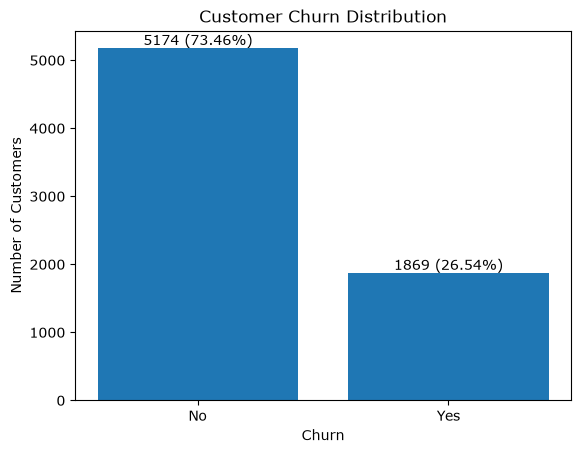

In [3]:

# Count customers in each churn category
churn_counts = df["Churn"] . value_counts()
churn_percentage = df["Churn"] . value_counts(normalize=True) * 100

# Display counts and percentage
churn_summary = pd.DataFrame({
    "Churn" : churn_counts,
    "Percentage %" : churn_percentage.round(2)
})

display(churn_summary)

# Visualize Churn Distribution

plt.Figure(figsize=(10,5))
bars = plt.bar(churn_counts.index, churn_counts.values)

plt.title("Customer Churn Distribution")
plt.xlabel("Churn")
plt.ylabel("Number of Customers")

for bar, percentage in zip(bars, churn_percentage):
    plt.text(
        bar.get_x() + bar.get_width() / 2,
        bar.get_height() + 50,
        f"{int(bar.get_height())} ({percentage:.2f}%)",
        ha="center"
    )

plt.show()


### Churn Distribution – Findings

The analysis shows that 73.46% of customers stayed with the company, while 26.54% left.

The target variable is imbalanced because there are more customers who stayed than customers who left.

This is important for machine learning because accuracy alone may be misleading. Therefore, precision, recall, F1-score, and ROC-AUC will also be used to evaluate the models.



### 3.2-Contract Type vs Churn

In this section, we analyze the relationship between contract type and customer churn.

The dataset contains three contract types: Month-to-month, One year, and Two year.

The goal is to compare churn rates across these contract types and identify which customer groups have a higher risk of churn.


Customer Count by Cotract Type


Churn,No,Yes
Contract,,
Month-to-month,2220,1655
One year,1307,166
Two year,1647,48


Churn Percentage by Contract Type (%)


Churn,No,Yes
Contract,,
Month-to-month,57.29,42.71
One year,88.73,11.27
Two year,97.17,2.83


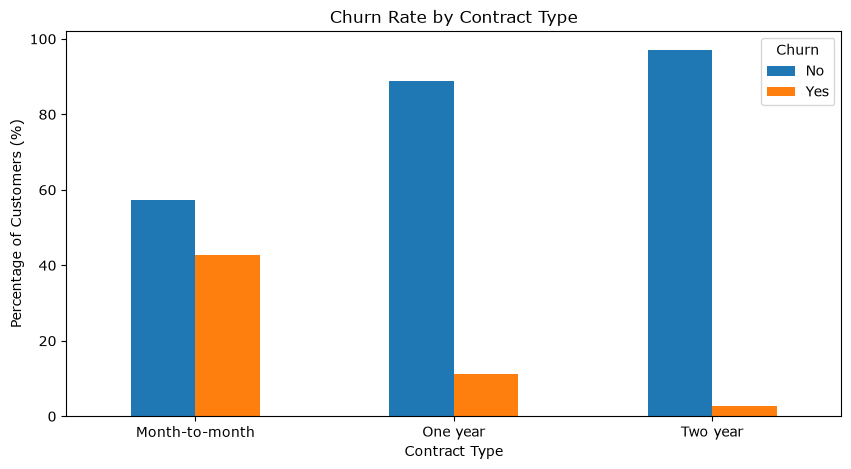

In [4]:
# Count customers by contract type and churn status

contract_counts = pd. crosstab(df["Contract"], df["Churn"])

print("Customer Count by Cotract Type")
display(contract_counts)

# Calculate churn percentages within each contract type
contract_percentages = pd.crosstab(df["Contract"], df["Churn"], normalize="index") * 100

print("Churn Percentage by Contract Type (%)")
display( contract_percentages. round(2))


# Visualize churn rates by contract type
contract_percentages.plot(kind="bar", figsize=(10,5))


plt.title("Churn Rate by Contract Type")
plt.xlabel("Contract Type")
plt.ylabel("Percentage of Customers (%)")
plt.xticks(rotation=0)
#plt.legend(title="Churn")
#plt.tight_layout()


plt.show()



### Contract Type vs Churn  – Findings

The analysis shows a clear relationship between contract type and customer churn.

- Month-to-month customers have the highest churn rate (42.71%).
- Customers with one-year contracts have a lower churn rate (11.27%).
- Customers with two-year contracts have the lowest churn rate (2.83%).

These results suggest that customers with longer contracts are less likely to leave the company.

From a business perspective, the company could investigate ways to encourage longer-term contracts and improve retention among month-to-month customers.



### 3.3-Tenure vs Churn

In this section, we explore the relationship between customer tenure and churn. Tenure represents the number of months a customer has stayed with the company.

The goal is to investigate whether customers who leave the company tend to have shorter tenure than customers who stay.


Tenure Statistics by Churn


,count,mean,std,min,25%,50%,75%,max
Churn,,,,,,,,
No,5174.0,37.57,24.11,0.0,15.0,38.0,61.0,72.0
Yes,1869.0,17.98,19.53,1.0,2.0,10.0,29.0,72.0


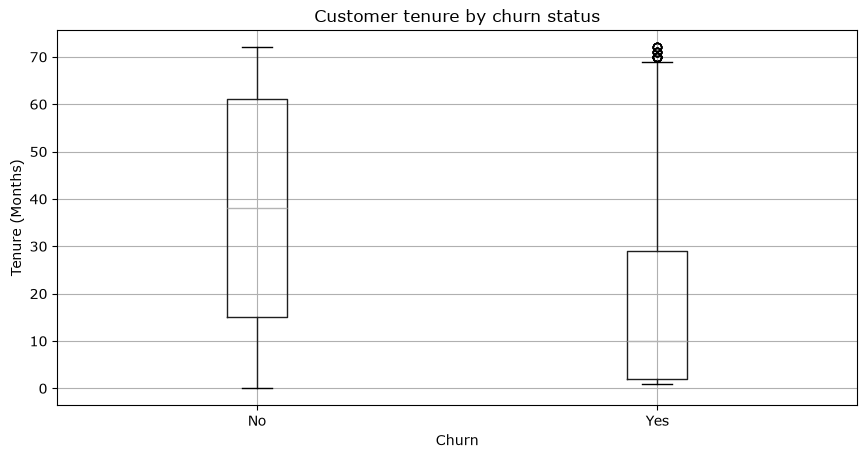

In [5]:

# Compare tenure statistics for customers who stayed and left

tenure_stats= df.groupby("Churn")["tenure"].describe().round(2)

print("Tenure Statistics by Churn")
display(tenure_stats)


# Visualize tenure distribution by churn status

df.boxplot(column="tenure", by="Churn", figsize=(10,5))

plt.title("Customer tenure by churn status")
plt.xlabel("Churn")
plt.ylabel("Tenure (Months)")
plt.suptitle("")

plt.show()


### Tenure vs Churn – Findings

The analysis shows that customers who left the company generally had shorter tenure than those who stayed.

- Customers who stayed had an average tenure of 37.57 months, compared to 17.98 months for customers who left.
- The median tenure was 38 months for customers who stayed and 10 months for those who left.
- The boxplot shows that churned customers are more concentrated at lower tenure values.

These findings suggest that newer customers may be more likely to churn.

From a business perspective, the company could focus on improving customer experience and retention during the early months of service.



### 3.4-Monthly Charges vs Churn

In this section, we explore the relationship between monthly charges and customer churn.MonthlyCharges represents the amount a customer pays each month.

The goal is to investigate whether customers who leave the company tend to have higher monthly charges than those who stay.


Monthly Charges Statistics by Churn


,count,mean,std,min,25%,50%,75%,max
Churn,,,,,,,,
No,5174.0,61.27,31.09,18.25,25.10,64.43,88.4,118.75
Yes,1869.0,74.44,24.67,18.85,56.15,79.65,94.2,118.35


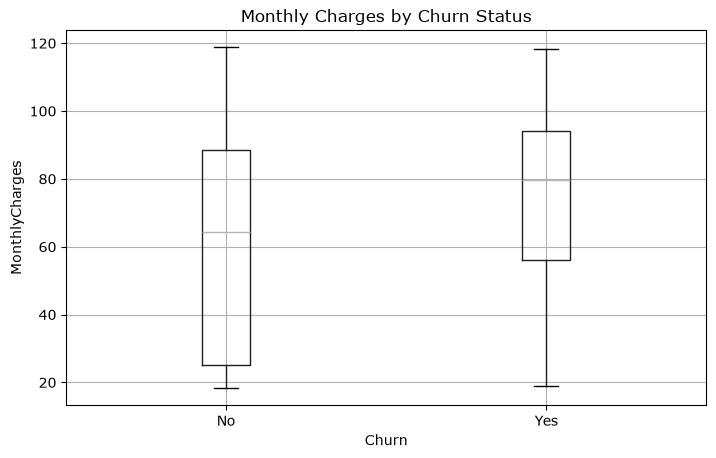

In [6]:
# Compare monthly charges statistics by churn status
monthly_charges_stats= df.groupby("Churn")["MonthlyCharges"].describe().round(2)

print("Monthly Charges Statistics by Churn")
display(monthly_charges_stats)

# Visualize monthly charges by churn status
df.boxplot(column="MonthlyCharges", by="Churn",figsize=(8,5))

plt.title("Monthly Charges by Churn Status")
plt.suptitle("")
plt.xlabel("Churn")
plt.ylabel("MonthlyCharges")

plt.show()


### Monthly Charges vs Churn – Findings

The analysis shows that customers who left the company generally had higher monthly charges than those who stayed.

- The average monthly charge was 74.44 for customers who left, compared to 61.27 for customers who stayed.
- The median monthly charge was also higher among customers who churned (79.65 vs. 64.43).
- The boxplot shows overlapping distributions, although churned customers generally had higher monthly charges.

These findings suggest an association between higher monthly charges and customer churn.

From a business perspective, the company could investigate whether pricing and perceived service value influence customer retention.



### 3.5-Customer Service and Payment Method vs Churn

This section compares churn rates across internet service types, payment methods, technical support, and online security services.

The goal is to identify which customer groups have higher churn rates and explore possible factors associated with customer retention.


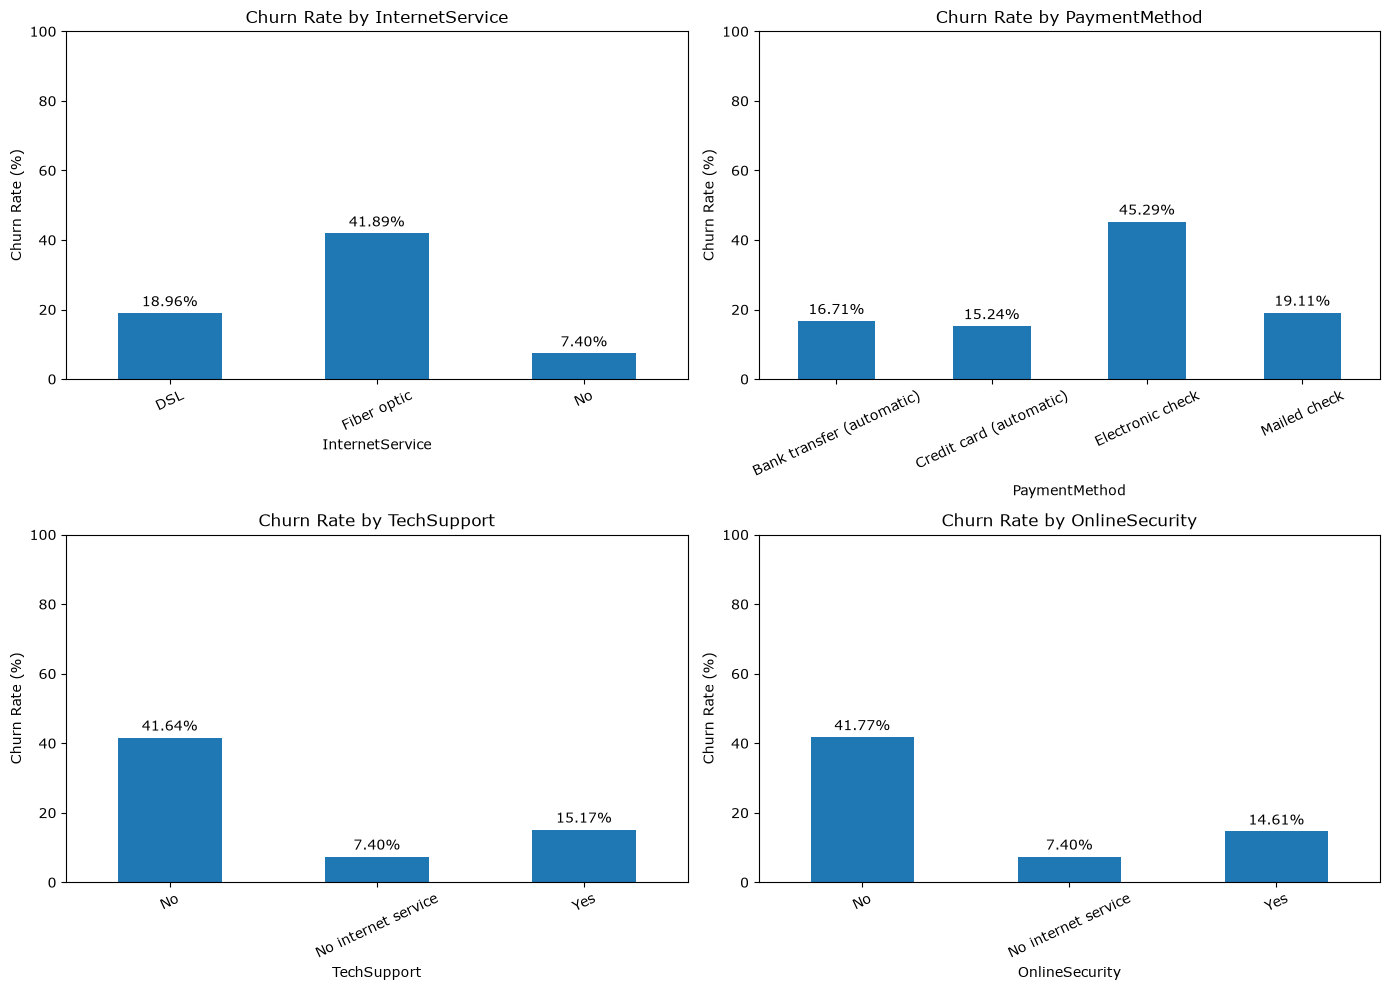

In [7]:

# Select categorical features for comparison
features = [
    "InternetService",
    "PaymentMethod",
    "TechSupport",
    "OnlineSecurity"
]

# Create four charts in one figure
fig, axes = plt.subplots(2, 2, figsize=(14, 10))

for feature, ax in zip(features, axes.flatten()):

    # Calculate churn rate within each category
    churn_rates = pd.crosstab(
        df[feature],
        df["Churn"],
        normalize="index"
    )["Yes"] * 100

    # Plot churn percentages
    churn_rates.plot(kind="bar", ax=ax)

    # Show percentage above each bar
    for bar in ax.patches:
        height = bar.get_height()
        ax.text(
            bar.get_x() + bar.get_width() / 2,
            height + 2,
            f"{height:.2f}%",
            ha="center"
        )


    ax.set_title(f"Churn Rate by {feature}")
    ax.set_xlabel(feature)
    ax.set_ylabel("Churn Rate (%)")
    ax.tick_params(axis="x", rotation=25)
    ax.set_ylim(0, 100)

plt.tight_layout()
plt.show()



### Customer Services and Payment Method – Findings

The analysis shows differences in churn rates across internet services, payment methods, technical support, and online security.

**Key Findings:**

- **Internet Service:** Fiber optic customers have the highest churn rate (41.89%), compared to DSL customers (18.96%) and customers without internet service (7.40%).
- **Payment Method:** Customers using electronic checks have the highest churn rate (45.29%), while automatic payment methods have lower churn rates.
- **Tech Support:** Customers without technical support have a higher churn rate (41.64%) than those with technical support (15.17%).
- **Online Security:** Customers without online security have a higher churn rate (41.77%) than those with online security (14.61%).

**Visualization Approach:**

Separate graphs were used earlier to explore important features such as contract type, tenure, and monthly charges in more detail.

For the remaining selected categorical features, four bar charts were combined into one figure to make the analysis more organized, reduce repetition, and allow easier comparison of churn rates across different customer groups.

**Business Insights:**

These findings suggest that internet service type, payment method, technical support, and online security are associated with customer churn.

The company could investigate customer satisfaction, service quality, and payment experiences to identify opportunities to improve customer retention. However, these relationships indicate associations rather than proven causal effects.



### 3.6-Additional Categorical Features – Overview

This section provides a summary of churn rates across additional customer characteristics and services.

The goal is to identify other potentially relevant features without creating a separate graph for every variable.


In [8]:
# Additional categorical features

additional_features = [
    "gender",
    "SeniorCitizen",
    "Partner",
    "Dependents",
    "PhoneService",
    "MultipleLines",
    "OnlineBackup",
    "DeviceProtection",
    "StreamingTV",
    "StreamingMovies",
    "PaperlessBilling"
]

# Calculate churn rates for each category
for feature in additional_features:
    churn_rates = pd.crosstab(
      df[feature],
      df["Churn"],
      normalize="index"
    ) ["Yes"] * 100

    print("Churn Rate by", feature, "(%)")
    display(churn_rates.round(2))

Churn Rate by gender (%)


gender
Female    26.92
Male      26.16
Name: Yes, dtype: float64

Churn Rate by SeniorCitizen (%)


SeniorCitizen
0    23.61
1    41.68
Name: Yes, dtype: float64

Churn Rate by Partner (%)


Partner
No     32.96
Yes    19.66
Name: Yes, dtype: float64

... (12 outputs left out)

Churn Rate by StreamingMovies (%)


StreamingMovies
No                     33.68
No internet service     7.40
Yes                    29.94
Name: Yes, dtype: float64

Churn Rate by PaperlessBilling (%)


PaperlessBilling
No     16.33
Yes    33.57
Name: Yes, dtype: float64


### Additional Categorical Features – Findings

The analysis shows differences in churn rates across customer characteristics and services.

**Key Findings:**

- **Gender:** Churn rates are almost the same for female (26.92%) and male (26.16%) customers.
- **Senior Citizens:** Senior customers have a higher churn rate (41.68%) than non-senior customers (23.61%).
- **Partner and Dependents:** Customers without partners (32.96%) or dependents (31.28%) have higher churn rates than those with partners (19.66%) or dependents (15.45%).
- **Phone Services:** Churn rates are relatively similar across phone service and multiple-line categories.
- **Online Backup:** Customers without online backup have a higher churn rate (39.93%) than those with online backup (21.53%).
- **Device Protection:** Customers without device protection have a higher churn rate (39.13%) than those with protection (22.50%).
- **Streaming Services:** Churn rates differ only slightly between customers with and without streaming TV or movies.
- **Paperless Billing:** Customers using paperless billing have a higher churn rate (33.57%) than those who do not (16.33%).

**Overall Findings:**

Customer characteristics such as age group, partner status, and dependents, as well as services such as online backup and device protection, show noticeable differences in churn rates.

Gender, phone services, and streaming services show smaller differences.

These findings suggest possible associations with customer churn, but they do not establish causation. Statistical tests will be used to investigate whether selected relationships are statistically significant.



## Step 4 - Statistical Analysis

Statistical tests are used to investigate whether the relationships observed during EDA are statistically significant.

### 1- Chi-Square Test: Contract Type vs Churn

The Chi-square test of independence is used to examine the relationship between two categorical variables.

**Null Hypothesis (H0):** Contract type and customer churn are independent.

**Alternative Hypothesis (H1):** Contract type and customer churn are associated.

The significance level is set at 0.05.


In [9]:

# Create a contingency table
contract_table = pd.crosstab(df["Contract"], df["Churn"])

print("Contract Type vs Churn")
display(contract_table)

# Perform Chi-square test
chi2, p_value, dof, expected = chi2_contingency(contract_table)

print("Chi-square statitics:", round(chi2,2))
print("P-value:", p_value)
print("Degrees of freedom:", dof)

Contract Type vs Churn


Churn,No,Yes
Contract,,
Month-to-month,2220,1655
One year,1307,166
Two year,1647,48


Chi-square statitics: 1184.6
P-value: 5.863038300673391e-258
Degrees of freedom: 2



### Chi-Square Test – Findings

The Chi-square test was performed to examine the relationship between contract type and customer churn.

**Results:**
- Chi-square statistic: 1184.60
- P-value: < 0.001
- Degrees of freedom: 2
- Significance level: 0.05

Since the p-value is below 0.05, the null hypothesis is rejected.

The results provide strong statistical evidence of an association between contract type and customer churn. This supports the earlier EDA findings, where month-to-month customers had a higher churn rate than customers with one-year or two-year contracts.

However, statistical significance does not imply causation.



### 2- Mann–Whitney U Test: Tenure vs Churn

The Mann–Whitney U test is used to compare tenure distributions between customers who stayed and customers who left.

**Null Hypothesis (H0):** The tenure distributions are the same for both groups.

**Alternative Hypothesis (H1):** The tenure distributions differ between the two groups.

The significance level is set at 0.05.


In [10]:

# Separate tenure values by churn status
tenure_yes = df[df["Churn"] == "Yes"]["tenure"]
tenure_no = df[df["Churn"] == "No"]["tenure"]

# Perform Mann–Whitney U test
u_stat, p_value = mannwhitneyu(
    tenure_yes,
    tenure_no,
    alternative="two-sided" 
)


print("Mann Whitney U Statistics:", u_stat)
print("P-value:", p_value)

Mann Whitney U Statistics: 2515538.0
P-value: 2.419635517951866e-208



### Mann–Whitney U Test – Tenure Findings

The Mann–Whitney U test was performed to compare tenure distributions between customers who stayed and customers who left.

**Results:**
- U statistic: 2,515,538
- P-value: < 0.001
- Significance level: 0.05

Since the p-value is below 0.05, the null hypothesis is rejected.

The results indicate a statistically significant difference in tenure distributions between the two groups.

This supports the earlier EDA findings, where customers who churned had a lower median tenure (10 months) than customers who stayed (38 months).

These findings suggest that shorter tenure is associated with customer churn. However, the test does not establish causation.



### 3- Mann–Whitney U Test: Monthly Charges vs Churn

This test examines whether monthly charge distributions differ between customers who stayed and customers who left.

**Null Hypothesis (H0):** Monthly charge distributions are the same for both groups.

**Alternative Hypothesis (H1):** Monthly charge distributions differ between the two groups.

The significance level is set at 0.05.


In [11]:
# Separate monthly charges by churn status
monthlycharges_yes = df[df["Churn"] == "Yes"]["MonthlyCharges"]
monthlycharges_no = df[df["Churn"] == "No"]["MonthlyCharges"]

# Perform Mann–Whitney U test
u_stat, p_value = mannwhitneyu(
    monthlycharges_yes,
    monthlycharges_no,
    alternative="two-sided"
)

print("Mann whitney u statistics:", u_stat)
print("P-value:", p_value)

Mann whitney u statistics: 6003125.5
P-value: 3.311627651988585e-54



### Mann–Whitney U Test – Monthly Charges Findings

The Mann–Whitney U test was performed to compare monthly charge distributions between customers who stayed and customers who left.

**Results:**
- U statistic: 6,003,125.5
- P-value: < 0.001
- Significance level: 0.05

Since the p-value is below 0.05, the null hypothesis is rejected.

The results indicate a statistically significant difference in monthly charge distributions between the two groups.

This supports the earlier EDA findings, where customers who churned had higher average monthly charges (74.44) compared to customers who stayed (61.27).

These findings suggest an association between monthly charges and customer churn, but they do not establish causation.



## Step 5 - Data Cleaning and Preprocessing

This section prepares the dataset for machine learning by handling data quality issues, converting data types, and preparing features.

### Handling Missing Values in TotalCharges

The initial data quality check identified 11 blank entries in the `TotalCharges` column. The column was stored as text instead of a numeric data type.

First, the column will be converted to a numeric format, and the blank entries will be identified as missing values (`NaN`). An appropriate method for handling these missing values will then be selected.


In [12]:
# Convert TotalCharges to numeric
df["TotalCharges"] = pd.to_numeric(
    df["TotalCharges"],
    errors="coerce"
)

# Check the data type and missing values
print("Data Type:", df["TotalCharges"].dtype)
print("Missing values:", df["TotalCharges"].isnull().sum())

Data Type: float64
Missing values: 11


In [13]:

# Examine customers with missing TotalCharges
missing_charges = df[df["TotalCharges"].isnull()]

display(missing_charges[["tenure", "MonthlyCharges", "TotalCharges", "Churn"]])

print("Tenure values:", missing_charges["tenure"].unique())


,tenure,MonthlyCharges,TotalCharges,Churn
488,0,52.55,NaN,No
753,0,20.25,NaN,No
936,0,80.85,NaN,No
1082,0,25.75,NaN,No
1340,0,56.05,NaN,No
3331,0,19.85,NaN,No
3826,0,25.35,NaN,No
4380,0,20.00,NaN,No
5218,0,19.70,NaN,No
6670,0,73.35,NaN,No


Tenure values: [0]


In [14]:
df["TotalCharges"] = df["TotalCharges"].fillna(0)


### Reasoning for Zero Imputation

I considered forward fill, backward fill, and median imputation. However, since each row represents a different customer, forward and backward filling could assign another customer's charges.

All 11 missing values belong to customers with zero tenure. Therefore, I chose to replace these missing values with 0, assuming that customers with zero tenure have not yet accumulated any charges.

After cleaning, the TotalCharges column contains no missing values and has a numeric data type (float64).


In [15]:
# Verify TotalCharges after cleaning

print("Missing Values:", df["TotalCharges"].isnull().sum())
print("Data Type:", df["TotalCharges"].dtype)
print("Total Charges for 0 tenure customers:")
display(df.loc[df["tenure"] == 0, ["tenure", "TotalCharges"]])

Missing Values: 0
Data Type: float64
Total Charges for 0 tenure customers:


,tenure,TotalCharges
488,0,0.0
753,0,0.0
936,0,0.0
1082,0,0.0
1340,0,0.0
3331,0,0.0
3826,0,0.0
4380,0,0.0
5218,0,0.0
6670,0,0.0



### Feature and Target Selection

The dataset is divided into input features (X) and the target variable (y).

The `Churn` column is selected as the target variable, while `customerID` is excluded because it is a unique identifier rather than a meaningful predictive feature.


In [16]:
# Separate features and target

X = df.drop(columns=["customerID", "Churn"])
y = df["Churn"]

# Check the dimensions
print("Features shape:", X.shape)
print("Target shape:", y.shape)
display(X.head())

Features shape: (7043, 19)
Target shape: (7043,)


,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,InternetService,OnlineSecurity,OnlineBackup,DeviceProtection,TechSupport,StreamingTV,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges
0,Female,0,Yes,No,1,No,No phone service,DSL,No,Yes,No,No,No,No,Month-to-month,Yes,Electronic check,29.85,29.85
1,Male,0,No,No,34,Yes,No,DSL,Yes,No,Yes,No,No,No,One year,No,Mailed check,56.95,1889.50
2,Male,0,No,No,2,Yes,No,DSL,Yes,Yes,No,No,No,No,Month-to-month,Yes,Mailed check,53.85,108.15
3,Male,0,No,No,45,No,No phone service,DSL,Yes,No,Yes,Yes,No,No,One year,No,Bank transfer (automatic),42.30,1840.75
4,Female,0,No,No,2,Yes,No,Fiber optic,No,No,No,No,No,No,Month-to-month,Yes,Electronic check,70.70,151.65



### Train/Test Split

The dataset is divided into 80% training data and 20% testing data.

The training set will be used to train the machine learning models, while the test set will be used to evaluate their performance on unseen data. Stratified sampling is used to maintain approximately the same churn distribution in both sets.


In [17]:

# Split data into training and testing sets
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=42,
    stratify=y
)

# Check the dimensions
print("X_train:", X_train.shape)
print("X_test:", X_test.shape)
print("y_train:", y_train.shape)
print("y_test:", y_test.shape)

X_train: (5634, 19)
X_test: (1409, 19)
y_train: (5634,)
y_test: (1409,)



### Categorical Encoding and Feature Scaling

The dataset contains both categorical and numerical features.

- One-hot encoding will be used to convert categorical variables into numerical features without introducing an artificial order.

- Standard scaling will be applied to numerical features to support Logistic Regression.

- Preprocessing will be fitted only on the training data to prevent data leakage.


In [18]:
# Identify categorical and numerical features
categorical_features = X_train.select_dtypes(include=["object", "str"]).columns
numerical_features = X_train.select_dtypes(include=["number"]).columns

# Treat SeniorCitizen as a binary categorical feature (Exclude SeniorCitizen from scaling because it is already a binary (0/1) feature.)
numerical_features = numerical_features.drop("SeniorCitizen") 

print("Categorical featurres:")
print(categorical_features.tolist())

print("\nNumerical features:")
print(numerical_features.tolist())

Categorical featurres:
['gender', 'Partner', 'Dependents', 'PhoneService', 'MultipleLines', 'InternetService', 'OnlineSecurity', 'OnlineBackup', 'DeviceProtection', 'TechSupport', 'StreamingTV', 'StreamingMovies', 'Contract', 'PaperlessBilling', 'PaymentMethod']

Numerical features:
['tenure', 'MonthlyCharges', 'TotalCharges']


### Create a preprocesisng pipeline

In [19]:

# create preprocessing steps
preprocessor = ColumnTransformer(transformers=[
    ("cat", OneHotEncoder(handle_unknown="ignore"), categorical_features ),
    ("num", StandardScaler(), numerical_features)
   ], remainder="passthrough"
)

print("Preprocessing pipeline created successfully")

Preprocessing pipeline created successfully



## Step 6 - Model Building and Evaluation

### Baseline Model: Logistic Regression

Logistic Regression is used as the baseline model to predict customer churn. A pipeline combines preprocessing and model training to ensure that the same transformations are applied consistently to training and testing data.


In [20]:

# create a pipeline with preprocessing and logistic regression
logistic_model = Pipeline(steps=[
    ("preprocessor", preprocessor),
    ("classifier", LogisticRegression(max_iter=1000))
])

print("Logistic regression pipeline created successfully")

Logistic regression pipeline created successfully


### Train the Logistic Regression Model

In [21]:
# Train the Logistic Regression model
logistic_model.fit(X_train,y_train)

print("Logistic Regression model trained successfully")

Logistic Regression model trained successfully



### Making Predictions with Logistic Regression

The trained Logistic Regression model is used to predict customer churn on the test dataset. The predictions will later be compared with actual churn values to evaluate the model's performance.


In [22]:
# Predict customer churn on the test data
y_pred_logistic = logistic_model.predict(X_test)

# Display the first 10 predictions
print("Showing first 10 predictions:")
print(y_pred_logistic[:10])

Showing first 10 predictions:
['No' 'Yes' 'No' 'No' 'No' 'Yes' 'No' 'No' 'No' 'No']



### Logistic Regression Model Evaluation

The Logistic Regression model is evaluated using Accuracy, Precision, Recall, F1-score, and ROC-AUC. These metrics help assess how effectively the model predicts customer churn.


In [23]:

# Calculate evaluation metrics
accuracy = accuracy_score(y_test, y_pred_logistic)
precision = precision_score(y_test, y_pred_logistic, pos_label="Yes")
recall = recall_score(y_test, y_pred_logistic, pos_label="Yes")
f1 = f1_score(y_test, y_pred_logistic, pos_label="Yes")

# Predict churn probabilities for ROC-AUC
y_prob_logistic = logistic_model.predict_proba(X_test)[:, 1]
roc_auc = roc_auc_score(y_test, y_prob_logistic)

#display results
print("Accuracy:", round(accuracy,4))
print("Precision:", round(precision,4))
print("Recall:", round(recall,4))
print("F1:", round(f1,4))
print("ROC-AUC:", round(roc_auc,4))



Accuracy: 0.8055
Precision: 0.6572
Recall: 0.5588
F1: 0.604
ROC-AUC: 0.842



#### Logistic Regression – Results and Interpretation

The Logistic Regression baseline model achieved an accuracy of **80.55%**, precision of **65.72%**, recall of **55.88%**, F1-score of **60.40%**, and ROC-AUC of **0.8420**.

The model demonstrates good overall predictive performance and can reasonably distinguish between customers who churn and those who stay.

However, the recall score indicates that approximately 44% of actual churn customers were not identified. This is an important limitation because identifying customers at risk of leaving is a key business objective.

The baseline results will be used to compare the performance of the Random Forest model and evaluate potential improvements.



### Confusion Matrix – Logistic Regression

A confusion matrix is used to examine correct and incorrect predictions made by the Logistic Regression model. It helps to identify how many churn and non-churn customers were correctly classified and how many were misclassified.


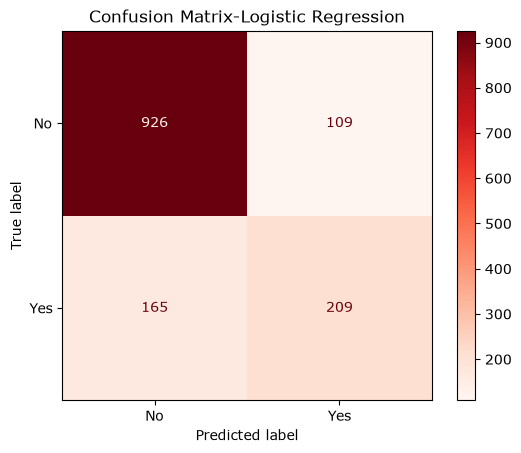

In [24]:

# Calculate confusion matrix
cm = confusion_matrix(y_test, y_pred_logistic, labels=["No","Yes"])

# Display confusion matrix
disp = ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=["No", "Yes"]
)

disp.plot(cmap="Reds")
plt.title("Confusion Matrix-Logistic Regression")
plt.show()



#### Confusion Matrix – Findings

The Logistic Regression model correctly classified 926 non-churn customers (True Negatives) and 209 churn customers (True Positives).

However, 109 non-churn customers were incorrectly classified as churn (False Positives), while 165 actual churn customers were incorrectly classified as non-churn (False Negatives).

The model missed approximately **44.12% of actual churn customers**, highlighting a limitation in identifying customers at risk of leaving.

Reducing false negatives and improving recall will be important when evaluating alternative models and optimization techniques.



### Random Forest Classifier

Random Forest is an ensemble learning algorithm that combines multiple decision trees to make predictions.

It is used as a second classification model to predict customer churn. Its performance will be compared with the Logistic Regression baseline model to determine whether it provides better results.


In [25]:

# Create a pipeline with preprocessing and Random Forest
rf_model = Pipeline(steps=[
    ("Preprocessor" , preprocessor),
    ("classifier", RandomForestClassifier(
        n_estimators=100,
        random_state=42
    ))
])

print("Random Forest pipeline created successfully")

Random Forest pipeline created successfully



#### Training the Random Forest Model

The Random Forest model is trained using the same training dataset as Logistic Regression to ensure a fair comparison between the two models.


In [26]:
rf_model.fit(X_train,y_train)

print("Random Forest model trained successfully")


Random Forest model trained successfully



#### Making Predictions with Random Forest

The trained Random Forest model is used to predict customer churn on the test dataset. These predictions will be compared with actual churn values to evaluate the model's performance.


In [27]:
# Predict customer churn using Random Forest
y_pred_rf = rf_model.predict(X_test)

# Display first 10 predictions
print("Showing first 10 predictions")
print(y_pred_rf[:10])


Showing first 10 predictions
['No' 'Yes' 'No' 'No' 'No' 'No' 'No' 'No' 'No' 'No']



#### Random Forest Model Evaluation

The Random Forest model is evaluated using Accuracy, Precision, Recall, F1-score, and ROC-AUC. The results will be compared with the Logistic Regression baseline to assess differences in predictive performance.


In [28]:

# calculate evaluation metrics
rf_accuracy = accuracy_score(y_test, y_pred_rf)
rf_precision = precision_score(y_test, y_pred_rf, pos_label="Yes")
rf_recall = recall_score(y_test, y_pred_rf, pos_label="Yes")
rf_f1 = f1_score(y_test, y_pred_rf, pos_label="Yes")

# Predict churn probabilities for ROC-AUC
y_prob_rf = rf_model.predict_proba(X_test)[:,1]
rf_roc_auc = roc_auc_score(y_test, y_prob_rf)

# Display results
print("Accurcay:", round(rf_accuracy, 4))
print("Precision:", round(rf_precision, 4))
print("Recall:", round(rf_recall, 4))
print("F1:", round(rf_f1, 4))
print("ROC-AUC:", round(rf_roc_auc, 4))


Accurcay: 0.7814
Precision: 0.61
Recall: 0.4893
F1: 0.543
ROC-AUC: 0.8203



#### Random Forest – Results and Interpretation

The Random Forest model achieved an accuracy of **78.14%**, precision of **61.00%**, recall of **48.93%**, F1-score of **54.30%**, and ROC-AUC of **0.8203**.

Although the model demonstrates reasonable predictive performance, it performs worse than the Logistic Regression baseline across all five evaluation metrics.

In particular, the lower recall indicates that Random Forest misses approximately 51% of actual churn customers, which is a significant limitation for customer retention.

These findings suggest that Logistic Regression is currently the stronger model. Further improvements, such as hyperparameter tuning or adjusting the classification threshold, will be explored.



#### Confusion Matrix – Random Forest

The confusion matrix is used to evaluate the Random Forest model by comparing actual and predicted churn values. It shows the number of correctly and incorrectly classified customers, including false negatives and false positives.


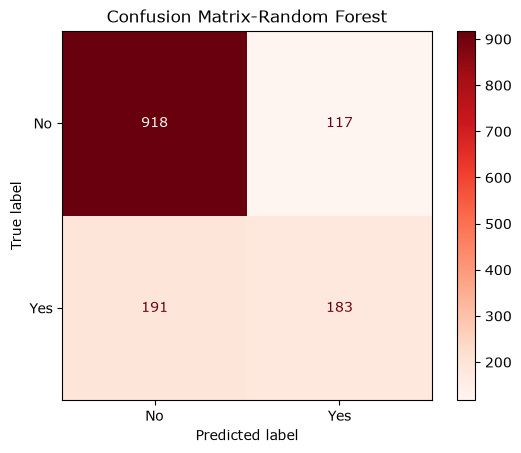

In [29]:
# Calculate confusion matrix
cm_rf = confusion_matrix(y_test, y_pred_rf, labels=["No", "Yes"])

# Display confusion matrix
disp_rf = ConfusionMatrixDisplay(
    confusion_matrix=cm_rf,
    display_labels=["No", "Yes"]
)

disp_rf.plot(cmap="Reds")
plt.title("Confusion Matrix-Random Forest")
plt.show()


#### Random Forest Confusion Matrix – Findings

The Random Forest model correctly classified 918 non-churn customers (True Negatives) and 183 churn customers (True Positives).

However, 117 non-churn customers were incorrectly classified as churn (False Positives), while 191 actual churn customers were missed (False Negatives).

The model failed to identify approximately **51.07% of actual churn customers**, indicating relatively low recall.

Compared with Logistic Regression, Random Forest identified 26 fewer churn customers and produced more false negatives. This suggests that Logistic Regression is currently more effective at identifying customers at risk of leaving.



## Step 7 - Model Comparison

The performance of Logistic Regression and Random Forest is compared using Accuracy, Precision, Recall, F1-score, and ROC-AUC.

Both models were evaluated on the same test dataset to ensure a consistent comparison. Particular attention is given to recall because identifying customers at risk of churn is an important business objective.


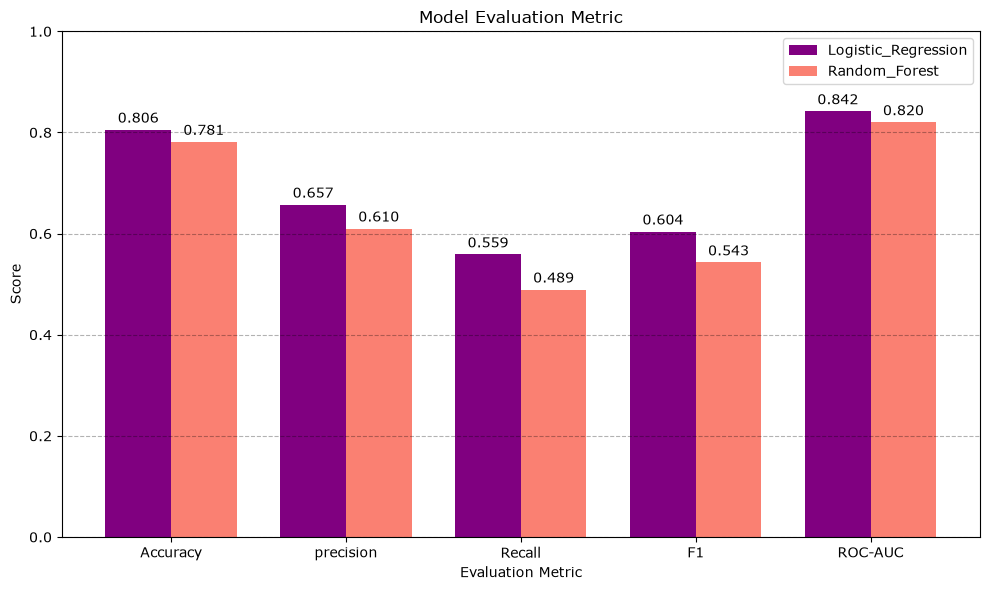

In [30]:
# Compare evaluation metrics of both models
model_comparison = pd.DataFrame({
    "Metric" : ["Accuracy", "precision", "Recall", "F1", "ROC-AUC"],
    "Logistic_Regression" : [accuracy, precision, recall, f1, roc_auc],
    "Random_Forest" : [rf_accuracy, rf_precision, rf_recall, rf_f1, rf_roc_auc]
})

#display(model_comparison.round(4))

# Visualize model performance comparison
ax = model_comparison.set_index("Metric").plot(
    kind="bar",
    figsize=(10,6),
    color=["purple", "salmon"],
    width=0.75
)

for container in ax.containers:
    ax.bar_label(container, fmt="%.3f", padding=3)

plt.title("Model Evaluation Metric")
plt.xlabel("Evaluation Metric")
plt.ylabel("Score")
plt.xticks(rotation=0)
plt.ylim(0,1)
plt.tight_layout()
plt.grid(axis="y", linestyle="--", alpha=0.3, color="Black")
plt.show()


### Model Comparison – Findings

Logistic Regression outperformed Random Forest across all five evaluation metrics.

Logistic Regression achieved higher accuracy (80.55%), precision (65.72%), recall (55.88%), F1-score (60.40%), and ROC-AUC (0.8420).

The difference in recall is particularly important. Logistic Regression identified more customers who actually churned, while Random Forest missed a larger proportion of these customers.

Therefore, Logistic Regression is currently the better-performing model for this dataset. However, further optimization is needed to improve recall and reduce the number of missed churn customers.



## Step 8 - Model Improvement

### Checking for Overfitting and Underfitting

Before improving the models, their performance on training and testing data is compared to identify possible overfitting or underfitting.

A large difference between training and testing accuracy may indicate overfitting, while low performance on both datasets may indicate underfitting.


In [31]:
# compare trainig and testing accuracy
print("Logistic Regression:")
print("Training Accuracy -", round(logistic_model.score(X_train, y_train),4))
print("Testing Accuracy -", round(logistic_model.score(X_test, y_test),4))

print("\nRandom Forest")
print("Training Accuracy -", round(rf_model.score(X_train,y_train),4))
print("Testng Accuracy -", round(rf_model.score(X_test,y_test),4))

Logistic Regression:
Training Accuracy - 0.806
Testing Accuracy - 0.8055

Random Forest
Training Accuracy - 0.998
Testng Accuracy - 0.7814



#### Overfitting Analysis – Findings

Logistic Regression achieved a training accuracy of **80.60%** and a testing accuracy of **80.55%**. The minimal difference suggests that the model generalizes well to unseen data, with no clear indication of significant overfitting.

In contrast, Random Forest achieved a training accuracy of **99.80%**, but its testing accuracy dropped to **78.14%**. This substantial difference indicates strong overfitting, suggesting that the model has learned patterns specific to the training data that do not generalize well.

These results support Logistic Regression as the stronger baseline model and highlight the need to reduce overfitting in Random Forest through model regularization and hyperparameter tuning.



### Random Forest Hyperparameter Tuning

The initial Random Forest model showed signs of overfitting, with a training accuracy of 99.80% and a testing accuracy of 78.14%.

Hyperparameter tuning will be performed to control model complexity and improve generalization to unseen data. Cross-validation will be used to select suitable parameter values without using the test dataset during tuning.


In [32]:
# Define hyperparameters for Random Forest tuning
param_grid = {
    "classifier__n_estimators": [100, 200],
    "classifier__max_depth": [5, 10, 15],
    "classifier__min_samples_leaf": [2, 5],
    "classifier__min_samples_split": [2, 5 ]
}

print("Hyperparameter grid created successfully")

Hyperparameter grid created successfully



#### Hyperparameter Optimization Using GridSearchCV

GridSearchCV is used with 5-fold cross-validation to evaluate different Random Forest hyperparameter combinations.

The F1-score for the churn class is used to select the best model, balancing precision and recall. Hyperparameter selection is performed using only the training data to avoid data leakage.


In [33]:

# Create a scorer for churn prediction
churn_f1_scorer = make_scorer(sklearn_f1_score, pos_label = "Yes")

# Create GridSearchCV
grid_search = GridSearchCV(
    estimator=rf_model,
    param_grid=param_grid,
    scoring=churn_f1_scorer,
    cv=5,
    n_jobs=1,
    error_score="raise"
)

print("GridSearchCV created successfully")

GridSearchCV created successfully


#### Run GridSearchCV

In [34]:
# Find the best Random Forest hyperparameters
grid_search.fit(X_train,y_train)

# Display the best results
print("Best Parameters:", grid_search.best_params_)
print("Best Cross Validation F1-score:", round(grid_search.best_score_,4))

Best Parameters: {'classifier__max_depth': 10, 'classifier__min_samples_leaf': 5, 'classifier__min_samples_split': 2, 'classifier__n_estimators': 100}
Best Cross Validation F1-score: 0.5779



#### Evaluation of Tuned Random Forest

The best hyperparameters were selected using GridSearchCV with 5-fold cross-validation.

The tuned Random Forest model is now evaluated on the held-out test dataset to assess its generalization performance and compare it with the original Random Forest model.


In [35]:

# Get the best tuned Random Forest model
best_rf_model = grid_search.best_estimator_

# Predict on the test dataset
y_pred_tuned_rf = best_rf_model.predict(X_test)
y_prob_tuned_rf = best_rf_model.predict_proba(X_test)[:, 1]

# Evaluate the tuned model
print("Tuned Random Forest Results:-")
print("Accuracy:", round(accuracy_score(y_test, y_pred_tuned_rf), 4))
print("Precision:", round(precision_score(y_test, y_pred_tuned_rf, pos_label="Yes"), 4))
print("Recall:", round(recall_score(y_test, y_pred_tuned_rf, pos_label="Yes"), 4))
print("F1-score:", round(sklearn_f1_score(y_test, y_pred_tuned_rf, pos_label="Yes"), 4))
print("ROC-AUC:", round(roc_auc_score(y_test, y_prob_tuned_rf), 4))

# Check overfitting
print("\nTraining Accuracy:", round(best_rf_model.score(X_train, y_train), 4))
print("Testing Accuracy:", round(best_rf_model.score(X_test, y_test), 4))


Tuned Random Forest Results:-
Accuracy: 0.807
Precision: 0.6796
Recall: 0.516
F1-score: 0.5866
ROC-AUC: 0.8409

Training Accuracy: 0.8447
Testing Accuracy: 0.807



### Impact of Hyperparameter Tuning - Findings

Hyperparameter tuning improved the Random Forest model across all five evaluation metrics.

- **Accuracy** increased from 78.14% to 80.70%.
- **Precision** improved from 61.00% to 67.96%.
- **Recall** increased from 48.93% to 51.60%, indicating better identification of customers who churn.
- **F1-score** increased from 54.30% to 58.66%.
- **ROC-AUC** improved from 82.03% to 84.09%.

Furthermore, the training–testing accuracy gap decreased from 21.66 to 3.77 percentage points, indicating substantially reduced overfitting.

**Conclusion:** Hyperparameter tuning improved the Random Forest model's performance and generalization. However, churn recall remains relatively low, suggesting that further improvement may be beneficial.



## Feature Engineering Based on EDA Findings

EDA revealed that customers with month-to-month contracts and shorter tenure have higher churn rates.

Based on these findings, a new binary feature, `New_Monthly_Customer`, was created:

- **1:** Customers with month-to-month contracts and tenure of 12 months or less.
- **0:** All other customers.

**Rationale:** Combining contract type and tenure helps identify a potentially high-risk customer segment. Customers in this segment have a churn rate of 51.35%, compared with 16.74% among other customers.

Although both variables already exist in the dataset, the engineered feature captures their combination explicitly.

The feature will be evaluated using Logistic Regression and Random Forest to determine whether it improves predictive performance.


In [36]:
# Keep the original dataset unchanged
df_fe = df.copy()

# Create a new feature based on EDA findings
df_fe["New_Monthly_Customer"] = (
   (df_fe["Contract"] == "Month-to-month") &
   (df_fe["tenure"] <=12)
).astype(int)

# Check the distribution of the new feature
print(df_fe["New_Monthly_Customer"].value_counts())

New_Monthly_Customer
0    5049
1    1994
Name: count, dtype: int64


In [37]:
# Calculate churn rate for the engineered feature
churn_by_new_feature = (
    df_fe.groupby("New_Monthly_Customer")["Churn"]
    .apply(lambda x:(x == "Yes").mean()*100)
)

print(churn_by_new_feature.round(2))

New_Monthly_Customer
0    16.74
1    51.35
Name: Churn, dtype: float64



### Feature Engineering – Findings

The engineered feature `New_Monthly_Customer` identifies 1,994 customers with month-to-month contracts and a tenure of 12 months or less.

The churn rate for this group is **51.35%**, compared with **16.74%** for other customers.

This indicates a strong association between the combined contract and tenure conditions and customer churn.

However, this relationship does not necessarily mean that the new feature will improve model performance, since the original variables are already available to the models.

The predictive value of this feature will therefore be evaluated separately.


### Prepare the engineered-feature dataset

In [38]:
# Prepare features and target for the engineered dataset
X_fe = df_fe.drop(columns=["customerID", "Churn"])
y_fe = df_fe["Churn"]

# Check the number of input features
print("Original Features:", X.shape[1])
print("Features after engineering:", X_fe.shape[1])

Original Features: 19
Features after engineering: 20



### Evaluating the Engineered Feature

To evaluate the impact of feature engineering, the dataset with 20 features is split into training and testing sets using the same settings as the original models.

This ensures a fair comparison between the original and feature-engineered models.


In [39]:
# Split the engineered dataset
X_train_fe, X_test_fe, y_train_fe, y_test_fe = train_test_split(
    X_fe,
    y_fe,
    test_size=0.2,
    random_state=42,
    stratify=y_fe
)

# Check the dataset dimensions
print("Training samples:", X_train_fe.shape[0])
print("Testing samples:" , X_test_fe.shape[0])
print("Number of features:", X_train_fe.shape[1])

Training samples: 5634
Testing samples: 1409
Number of features: 20



#### Logistic Regression with Engineered Features

A Logistic Regression model is trained using the engineered dataset containing 20 input features.

The same preprocessing approach and model settings are used to ensure a fair comparison with the original 19-feature Logistic Regression model.


In [40]:

# Update preprocessing to include the engineered feature
categorical_features_fe = X_train_fe.select_dtypes(
    include=["object", "str"]
).columns

numerical_features_fe = X_train_fe.select_dtypes(
    include=["number"]
).columns.drop("SeniorCitizen")

preprocessor_fe = ColumnTransformer(
    transformers=[
        ("cat", OneHotEncoder(handle_unknown="ignore"), categorical_features_fe),
        ("num", StandardScaler(), numerical_features_fe)
    ],
    remainder="passthrough"
)

# Create and train Logistic Regression with engineered features
logistic_fe_model = Pipeline(steps=[
    ("preprocessor", preprocessor_fe),
    ("classifier", LogisticRegression(max_iter=100))
])

logistic_fe_model.fit(X_train_fe, y_train_fe)

print("Feature-engineered Logistic Regression trained successfully!")


Feature-engineered Logistic Regression trained successfully!



#### Evaluation of Logistic Regression with Engineered Features

The feature-engineered Logistic Regression model is evaluated on the test dataset using accuracy, precision, recall, F1-score, and ROC-AUC.

The results will be compared with the original Logistic Regression model to assess the impact of the newly created feature.


In [41]:

# Predict churn using the engineered-feature model
y_pred_logistic_fe = logistic_fe_model.predict(X_test_fe)
y_prob_logistic_fe = logistic_fe_model.predict_proba(X_test_fe)[:, 1]

# Evaluate model performance
fe_accuracy = accuracy_score(y_test_fe, y_pred_logistic_fe)
fe_precision = precision_score(y_test_fe, y_pred_logistic_fe, pos_label="Yes")
fe_recall = recall_score(y_test_fe, y_pred_logistic_fe, pos_label="Yes")
fe_f1 = sklearn_f1_score(y_test_fe, y_pred_logistic_fe, pos_label="Yes")
fe_roc_auc = roc_auc_score(y_test_fe, y_prob_logistic_fe)

print("Feature-Engineered Logistic Regression Results:")
print("\nAccuracy:", round(fe_accuracy, 4))
print("Precision:", round(fe_precision, 4))
print("Recall:", round(fe_recall, 4))
print("F1-score:", round(fe_f1, 4))
print("ROC-AUC:", round(fe_roc_auc, 4))


Feature-Engineered Logistic Regression Results:

Accuracy: 0.8006
Precision: 0.6587
Recall: 0.516
F1-score: 0.5787
ROC-AUC: 0.8423



#### Random Forest with Engineered Features

The tuned Random Forest model is also evaluated using the engineered dataset containing 20 features.

The same hyperparameters are retained to assess whether the additional feature improves predictive performance.


In [42]:

# Create a new copy of the tuned Random Forest model
rf_fe_model = clone(best_rf_model)

# Train using 20 features
rf_fe_model.fit(X_train_fe, y_train_fe)

print("Feature-engineered Random Forest trained successfully!")


Feature-engineered Random Forest trained successfully!



#### Evaluation of Random Forest with Engineered Features

The feature-engineered Random Forest model is evaluated using accuracy, precision, recall, F1-score, and ROC-AUC.

The results are compared with the original tuned Random Forest model to assess the impact of feature engineering.


In [43]:

# Predict churn using the feature-engineered Random Forest
y_pred_rf_fe = rf_fe_model.predict(X_test_fe)
y_prob_rf_fe = rf_fe_model.predict_proba(X_test_fe)[:, 1]

# Evaluate model performance
rf_fe_accuracy = accuracy_score(y_test_fe, y_pred_rf_fe)
rf_fe_precision = precision_score(y_test_fe, y_pred_rf_fe, pos_label="Yes")
rf_fe_recall = recall_score(y_test_fe, y_pred_rf_fe, pos_label="Yes")
rf_fe_f1 = sklearn_f1_score(y_test_fe, y_pred_rf_fe, pos_label="Yes")
rf_fe_roc_auc = roc_auc_score(y_test_fe, y_prob_rf_fe)

print("Feature-Engineered Random Forest Results:")
print("\nAccuracy:", round(rf_fe_accuracy, 4))
print("Precision:", round(rf_fe_precision, 4))
print("Recall:", round(rf_fe_recall, 4))
print("F1-score:", round(rf_fe_f1, 4))
print("ROC-AUC:", round(rf_fe_roc_auc, 4))


Feature-Engineered Random Forest Results:

Accuracy: 0.8027
Precision: 0.6667
Recall: 0.5134
F1-score: 0.5801
ROC-AUC: 0.8405



#### Feature Engineering – Findings

A new feature, `New_Monthly_Customer`, was created to identify customers with month-to-month contracts and a tenure of 12 months or less.

The engineered feature was evaluated using both Logistic Regression and the tuned Random Forest model.

**Logistic Regression:**
- ROC-AUC increased slightly from 0.8420 to 0.8423.
- Precision increased from 0.6572 to 0.6587.
- Recall decreased from 0.5588 to 0.5160.
- F1-score decreased from 0.6040 to 0.5787.

**Random Forest:**
- ROC-AUC decreased from 0.8409 to 0.8405.
- F1-score decreased from 0.5866 to 0.5801.
- Accuracy, precision, and recall also decreased slightly.

**Conclusion:**

Although the engineered feature showed a strong association with churn during EDA, it did not improve overall model performance.

The original 19-feature Logistic Regression remains the preferred model because it achieves the highest F1-score and recall among the evaluated models, which are particularly important for identifying customers at risk of churn.



## Step 9- Final Model Comparison

The performance of Logistic Regression, Random Forest, tuned Random Forest, and the feature-engineered versions of Logistic Regression and tuned Random Forest is compared to identify the most suitable model for customer churn prediction.

The comparison focuses on accuracy, precision, recall, F1-score, and ROC-AUC, with particular attention to identifying customers at risk of churn.


,Metric,Logistic Regression,Original Random Forest,Tuned Random Forest,Logistic Regression + FE,Tuned Random Forest + FE
0,Accuracy,0.8055,0.7814,0.8070,0.8006,0.8027
1,Precision,0.6572,0.6100,0.6796,0.6587,0.6667
2,Recall,0.5588,0.4893,0.5160,0.5160,0.5134
3,F1-score,0.6040,0.5430,0.5866,0.5787,0.5801
4,ROC-AUC,0.8420,0.8203,0.8409,0.8423,0.8405


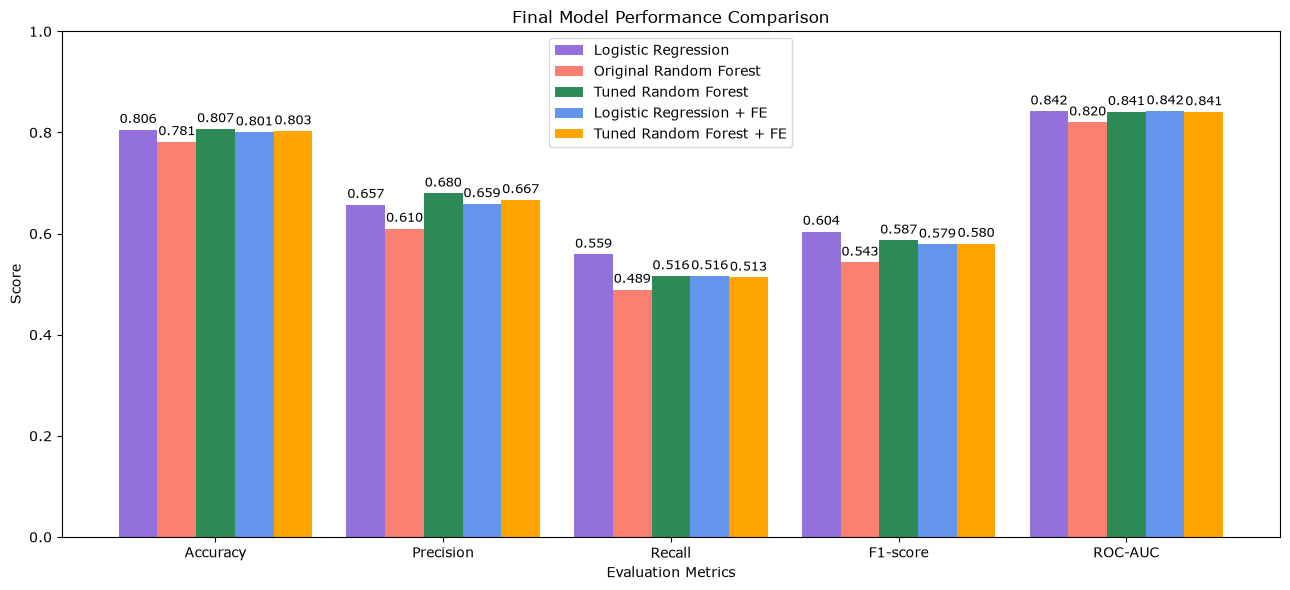

In [44]:

# Compare all five models
final_comparison = pd.DataFrame({
    "Metric": ["Accuracy", "Precision", "Recall", "F1-score", "ROC-AUC"],
    "Logistic Regression": [accuracy, precision, recall, f1, roc_auc],
    "Original Random Forest": [rf_accuracy, rf_precision, rf_recall, rf_f1, rf_roc_auc],
    "Tuned Random Forest": [
        accuracy_score(y_test, y_pred_tuned_rf),
        precision_score(y_test, y_pred_tuned_rf, pos_label="Yes"),
        recall_score(y_test, y_pred_tuned_rf, pos_label="Yes"),
        sklearn_f1_score(y_test, y_pred_tuned_rf, pos_label="Yes"),
        roc_auc_score(y_test, y_prob_tuned_rf)
    ],

    "Logistic Regression + FE": [
        fe_accuracy, fe_precision, fe_recall, fe_f1, fe_roc_auc
    ],

    "Tuned Random Forest + FE": [
        rf_fe_accuracy, rf_fe_precision, rf_fe_recall, rf_fe_f1, rf_fe_roc_auc
    ]    
})

display(final_comparison.round(4))


# Create final comparison chart
ax = final_comparison.set_index("Metric").plot(
    kind="bar",
    figsize=(13,6),
    color=["mediumpurple", "salmon", "seagreen", "cornflowerblue", "orange"],
    width=0.85
)

# Display scores above bars
for container in ax.containers:
    ax.bar_label(container, fmt="%.3f", padding=3, fontsize=9)


plt.title("Final Model Performance Comparison")
plt.xlabel("Evaluation Metrics")
plt.ylabel("Score")
plt.ylim(0,1)
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()



### Final Model Selection and Findings

Five models were evaluated using accuracy, precision, recall, F1-score, and ROC-AUC.

**Key Findings:**

- The tuned Random Forest achieved the highest accuracy (0.8070) and precision (0.6796).
- The original Logistic Regression achieved the highest recall (0.5588) and F1-score (0.6040).
- Logistic Regression with feature engineering achieved the highest ROC-AUC (0.8423), only slightly higher than the original Logistic   Regression (0.8420).
- Hyperparameter tuning improved Random Forest performance and reduced overfitting.
- Feature engineering did not provide a meaningful overall improvement for either model.

**Selected Model: Logistic Regression (19 features)**

The original Logistic Regression model was selected because it provides the best balance between precision and recall, achieving the highest F1-score among the evaluated models.

Its higher recall is particularly valuable for identifying customers who are likely to churn, allowing businesses to take proactive retention measures.

Although other models achieved slightly higher accuracy, precision, or ROC-AUC, Logistic Regression provides the strongest overall performance for the primary business objective.



### Logistic Regression Model Interpretation

The coefficients of the selected Logistic Regression model are analyzed to understand how customer characteristics influence the model's churn predictions.

Positive coefficients are associated with higher predicted odds of churn, while negative coefficients are associated with lower predicted odds, holding other model features constant.


In [45]:
# Extract the trained model components
fitted_preprocessor = logistic_model.named_steps["preprocessor"]
fitted_classifier = logistic_model.named_steps["classifier"]

# Get feature names after preprocessing
feature_names = fitted_preprocessor.get_feature_names_out()

# Create a table of model coefficients
coefficients_df = pd.DataFrame({
    "Feature": feature_names,
    "Coefficients": fitted_classifier.coef_[0]
})

# Sort coefficients
coefficients_df = coefficients_df.sort_values("Coefficients")

display(coefficients_df)

,Feature,Coefficients
41,num__tenure,-1.249501
34,cat__Contract_Two year,-0.770715
11,cat__InternetService_DSL,-0.660859
42,num__MonthlyCharges,-0.620723
35,cat__PaperlessBilling_No,-0.343703
13,cat__InternetService_No,-0.306057
15,cat__OnlineSecurity_No internet service,-0.306057
30,cat__StreamingMovies_No internet service,-0.306057
24,cat__TechSupport_No internet service,-0.306057
27,cat__StreamingTV_No internet service,-0.306057


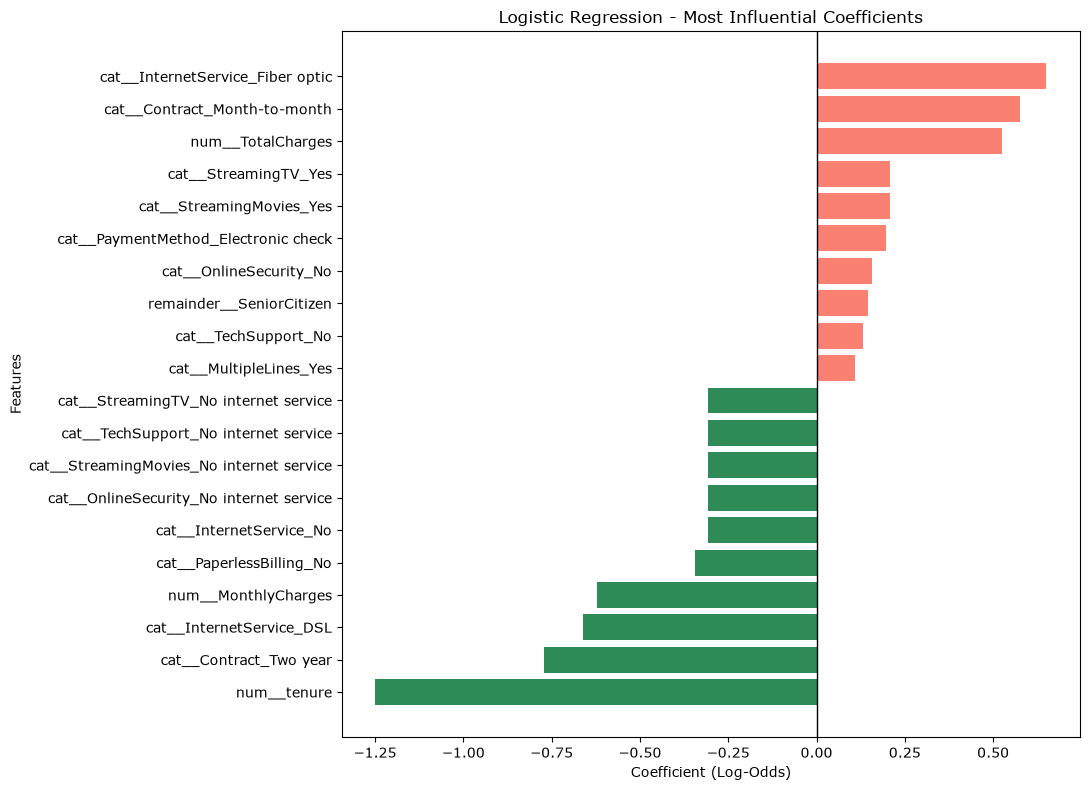

In [46]:
# Select the 10 most negative and 10 most positive coefficients
top_negative = coefficients_df.head(10)
top_positive = coefficients_df.tail(10)

important_coefficients = pd.concat([top_negative, top_positive])

# Visualize the coefficients
plt.figure(figsize=(11,8))
colors = [
    "seagreen" if value < 0 else "salmon"
    for value in important_coefficients["Coefficients"]
]

plt.barh(
    important_coefficients["Feature"],
    important_coefficients["Coefficients"],
    color=colors
)

plt.axvline(x=0, color="black", linewidth=1)
plt.title("Logistic Regression - Most Influential Coefficients")
plt.xlabel("Coefficient (Log-Odds)")
plt.ylabel("Features")
plt.tight_layout()
plt.show()



#### Logistic Regression Coefficient Interpretation – Findings

The coefficients of the selected Logistic Regression model were analyzed to understand how customer characteristics are associated with predicted churn.

**Key Findings:**

- **Customer Tenure:** Tenure has a strong negative coefficient (-1.2495), indicating that longer customer relationships are associated with lower predicted churn odds.
- **Contract Type:** Month-to-month contracts have a positive coefficient (+0.5761), while two-year contracts have a negative coefficient (-0.7707). This is consistent with the EDA findings showing higher churn among month-to-month customers.
- **Internet Service:** Fiber optic service has a positive coefficient (+0.6511), while DSL has a negative coefficient (-0.6609), suggesting different churn patterns across service types.
- **Monthly Charges:** Monthly charges have a negative coefficient (-0.6207), despite the positive overall association observed in EDA. This may reflect correlations with other variables included in the model.

**Interpretation:**

The coefficient analysis provides insight into how the model uses customer characteristics when predicting churn. Several patterns, particularly tenure and contract type, are consistent with the exploratory analysis.

However, coefficients represent associations rather than causal effects. Their interpretation should also consider feature scaling, correlated variables, and one-hot encoding.



## Step 10 – Business Insights and Recommendations

### Key Business Insights

The exploratory data analysis and machine learning results provide several insights into customer churn:

1. **Contract Type:** Month-to-month customers have the highest churn rate (42.71%), compared with one-year (11.27%) and two-year (2.83%) contract customers.

2. **Customer Tenure:** Customers with shorter tenure are more likely to churn, suggesting that the early stages of the customer relationship are particularly important.

3. **Monthly Charges:** Customers who churn tend to have higher monthly charges, indicating that pricing may be associated with customer retention.

4. **High-Risk Customer Segment:** Customers with month-to-month contracts and tenure of 12 months or less have a churn rate of 51.35%, compared with 16.74% for other customers.

### Business Recommendations

- **Improve Customer Onboarding:** Provide additional support and engagement during the first 12 months.
- **Encourage Longer Contracts:** Offer suitable incentives for month-to-month customers to consider longer-term plans.
- **Review Pricing and Value:** Investigate whether customers with higher monthly charges are receiving sufficient value.
- **Use Predictive Analytics:** Apply the selected Logistic Regression model to identify customers with elevated churn risk and prioritize retention efforts.

### Business Value

The selected model can support data-driven customer retention strategies by helping the business identify customers at risk of leaving.

By targeting high-risk customer segments, the company may improve customer satisfaction, reduce churn, and allocate retention resources more effectively.



## Step 11 – Save the Final Model for Deployment

The selected Logistic Regression model is saved using Joblib for integration into a Streamlit application.

The complete pipeline, including preprocessing and classification, is saved to ensure that new customer data is processed consistently before prediction.


In [47]:

# Create a folder for the saved model
model_dir = Path("models")
model_dir.mkdir(exist_ok=True)

# Save the trained Logistic Regression pipeline
joblib.dump(logistic_model, model_dir / "Churn_model.pkl")

print("Model saved succefully!")

Model saved succefully!
